In [ ]:
%matplotlib inline
import numpy as np, math
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

import matplotlib.pyplot as plt
from scipy.optimize import brentq

G=6.674e-11 
mE=5.972e24
mM=7.348e22
R=3.844e8


w=math.sqrt(G*(mE+mM)/R**3); T=2*math.pi/w   # angualr frequency for earth and moon 
fE=mM/(mE+mM)*R; fM=mE/(mE+mM)*R         # earh moon distances fro bary centre 
dr_approx=R*(mM/(3*mE))**(1/3)     # distance form moon to L2 point roughly 

def bodies(t):                         # earth moon positions at any time 
    c,s=math.cos(w*t),math.sin(w*t)
    return (-fE*c,-fE*s),(fM*c,fM*s)


def bodyvel(t):                                  # earth moon velocities at any time from differntiteing above 
    c,s=math.cos(w*t),math.sin(w*t)
    return (fE*w*s,-fE*w*c),(-fM*w*s,fM*w*c)

def init(dr):                                    # where the rocket starts, certain distance past moon 
    r=fM+dr                      
    return [r,0.0,0.0,w*r]       # co-rotating

# ---------- SciPy ----------
def rhs(t,s):
    x,y,vx,vy=s
    (xe,ye),(xm,ym)=bodies(t)
    dEx,dEy,dMx,dMy=x-xe,y-ye,x-xm,y-ym
    dE3=(dEx*dEx+dEy*dEy)**1.5; dM3=(dMx*dMx+dMy*dMy)**1.5
    return [vx,vy,-G*mE*dEx/dE3-G*mM*dMx/dM3,-G*mE*dEy/dE3-G*mM*dMy/dM3]    # rhs of diffetnial equation for accelration 

def run_scipy(dr,n=2000):
    sol=solve_ivp(rhs,[0,T],init(dr),method="DOP853",rtol=1e-12,atol=1e-4,dense_output=True)
    t=np.linspace(0,T,n); return t,sol.sol(t)

#------------Runga - kutta ---------------

#ef 

# ---------- Taylor expansion ----------
def acc_jerk(t,x,y,vx,vy):
    (xe,ye),(xm,ym)=bodies(t); (uex,uey),(umx,umy)=bodyvel(t)
    ax=ay=jx=jy=0.0
    for m,bx,by,bvx,bvy in ((mE,xe,ye,uex,uey),(mM,xm,ym,umx,umy)):
        dx,dy=x-bx,y-by; d2=dx*dx+dy*dy; d=math.sqrt(d2); d3=d2*d; d5=d3*d2
        wx,wy=vx-bvx,vy-bvy; dot=dx*wx+dy*wy
        ax+=-G*m*dx/d3; ay+=-G*m*dy/d3
        jx+=-G*m*(wx/d3-3*dot*dx/d5); jy+=-G*m*(wy/d3-3*dot*dy/d5)
    return ax,ay,jx,jy
def run_taylor(dr,h=10.0,store=200):
    x,y,vx,vy=init(dr); N=int(round(T/h)); h=T/N
    out=[]; t=0.0
    for k in range(N+1):
        if k%store==0 or k==N: out.append((t,x,y,vx,vy))
        ax,ay,jx,jy=acc_jerk(t,x,y,vx,vy)
        x_n=x+vx*h+ax*h*h/2+jx*h**3/6
        y_n=y+vy*h+ay*h*h/2+jy*h**3/6
        vx_n=vx+ax*h+jx*h*h/2
        vy_n=vy+ay*h+jy*h*h/2
        x,y,vx,vy=x_n,y_n,vx_n,vy_n; t+=h
    return np.array(out).T

def sep_scipy(dr,n=1500):
    t,Y=run_scipy(dr,n)
    mx=fM*np.cos(w*t); my=fM*np.sin(w*t)
    return t,np.hypot(Y[0]-mx,Y[1]-my),Y


def balance(dr):
    r=fM+dr
    return -G*mE/(r+fE)**2 - G*mM/dr**2 + w**2*r
dr_exact=brentq(balance,3e7,1e8,xtol=1e-3)
print("Moon period T = %.4f days"%(T/86400))
print("formula  dr = %.0f km"%(dr_approx/1e3))
print("optimal  dr = %.0f km  (formula is %.1f%% low)"%(dr_exact/1e3,100*(dr_exact-dr_approx)/dr_exact))

def sep_and_drift(t,x,y,dr):
    sep=np.hypot(x-fM*np.cos(w*t),y-fM*np.sin(w*t))
    # drift from the starting L2 spot, measured in the co-rotating frame
    xr=x*np.cos(w*t)+y*np.sin(w*t); yr=-x*np.sin(w*t)+y*np.cos(w*t)
    return sep,np.hypot(xr-(fM+dr),yr)

t,Y=run_scipy(dr_exact,2000); s1,d1=sep_and_drift(t,Y[0],Y[1],dr_exact)
print("SciPy : separation from Moon after 1 orbit = %.0f km (max %.0f km); drift from L2 = %.2f km"%(s1[-1]/1e3,s1.max()/1e3,d1[-1]/1e3))
tt,x,y,vx,vy=run_taylor(dr_exact,h=10.0); s2,d2=sep_and_drift(tt,x,y,dr_exact)
print("Taylor: separation from Moon after 1 orbit = %.0f km (max %.0f km); drift from L2 = %.2f km"%(s2[-1]/1e3,s2.max()/1e3,d2[-1]/1e3))
for fr in (0.99,0.995,1.001,1.01):
    tq,sq,_=sep_scipy(dr_exact*fr,1500); print("dr = %.3f x optimal -> max separation %.0f km"%(fr,sq.max()/1e3))

Moon period T = 27.2855 days
formula  dr = 61531 km
optimal  dr = 64522 km  (formula is 4.6% low)
SciPy : separation from Moon after 1 orbit = 64522 km (max 64522 km); drift from L2 = 0.01 km
Taylor: separation from Moon after 1 orbit = 64519 km (max 64522 km); drift from L2 = 4.37 km
dr = 0.990 x optimal -> max separation 103311 km
dr = 0.995 x optimal -> max separation 76093 km
dr = 1.001 x optimal -> max separation 931647 km
dr = 1.010 x optimal -> max separation 1326289 km


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


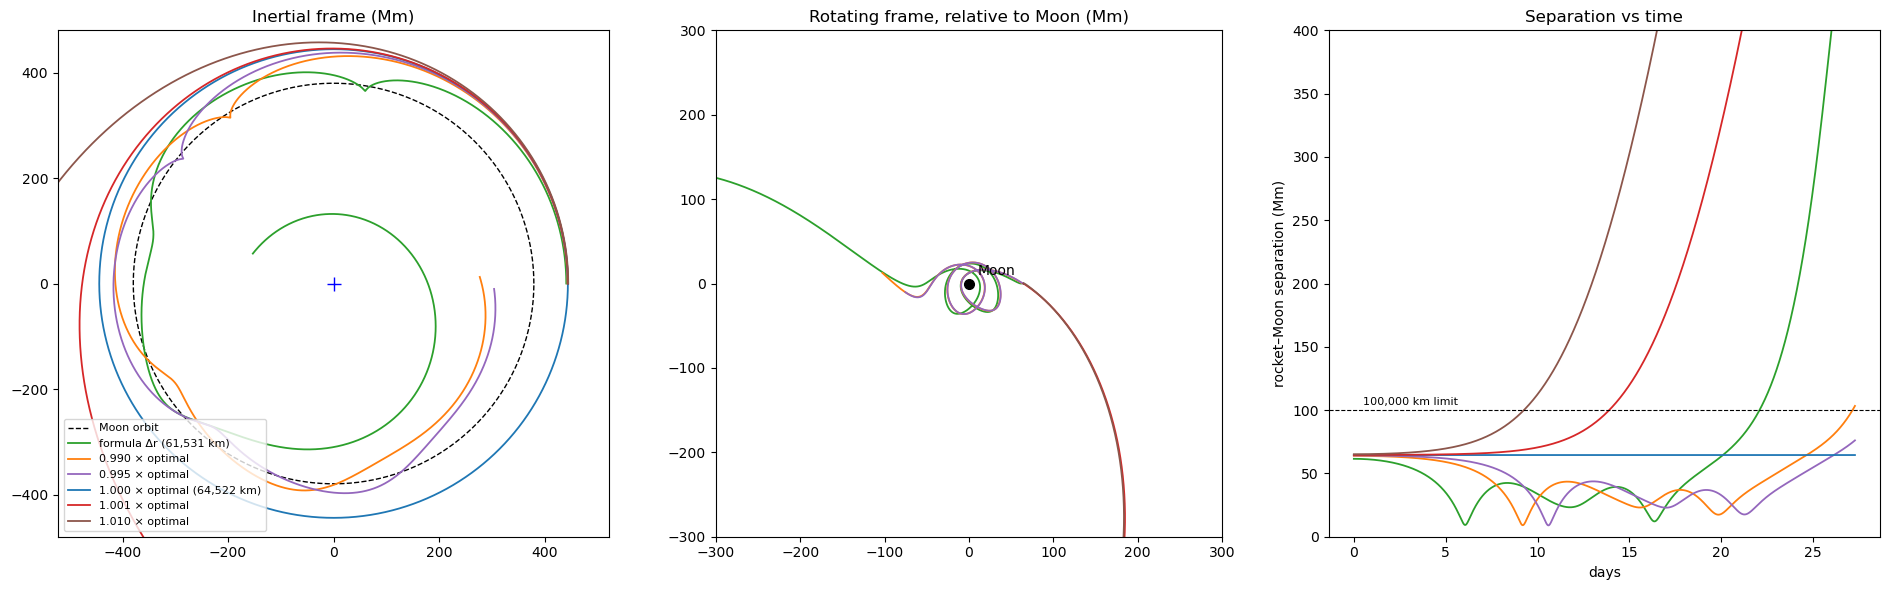

In [10]:
from scipy.optimize import brentq
def balance(dr):
    r=fM+dr; return -G*mE/(r+fE)**2 - G*mM/dr**2 + w**2*r
dr_ex=brentq(balance,3e7,1e8,xtol=1e-3)
scen=[("formula Δr (61,531 km)",dr_approx,"tab:green"),
      ("0.990 × optimal",0.990*dr_ex,"tab:orange"),
      ("0.995 × optimal",0.995*dr_ex,"tab:purple"),
      ("1.000 × optimal (64,522 km)",dr_ex,"tab:blue"),
      ("1.001 × optimal",1.001*dr_ex,"tab:red"),
      ("1.010 × optimal",1.010*dr_ex,"tab:brown")]
th=np.linspace(0,2*np.pi,500)
fig,ax=plt.subplots(1,3,figsize=(19,6))
ax[0].plot(fM*np.cos(th)/1e6,fM*np.sin(th)/1e6,"k--",lw=1,label="Moon orbit")
ax[0].plot(0,0,"b+",ms=10)
for name,dr,c in scen:
    t,Y=run_scipy(dr,3000)
    sep=np.hypot(Y[0]-fM*np.cos(w*t),Y[1]-fM*np.sin(w*t))
    ax[0].plot(Y[0]/1e6,Y[1]/1e6,c=c,lw=1.3,label=name)
    xr=Y[0]*np.cos(w*t)+Y[1]*np.sin(w*t)-fM; yr=-Y[0]*np.sin(w*t)+Y[1]*np.cos(w*t)
    ax[1].plot(xr/1e6,yr/1e6,c=c,lw=1.3)
    ax[2].plot(t/86400,sep/1e6,c=c,lw=1.3)
ax[0].set_title("Inertial frame (Mm)"); ax[0].axis("equal"); ax[0].legend(fontsize=8,loc="lower left")
ax[0].set_xlim(-450,450); ax[0].set_ylim(-450,450)
ax[1].plot(0,0,"ko",ms=7); ax[1].annotate("Moon",(0,0),textcoords="offset points",xytext=(6,6))
ax[1].set_title("Rotating frame, relative to Moon (Mm)"); ax[1].set_aspect("equal"); ax[1].set_xlim(-300,300); ax[1].set_ylim(-300,300)
ax[2].axhline(100,c="k",ls="--",lw=.8); ax[2].text(0.5,104,"100,000 km limit",fontsize=8)
ax[2].set_ylim(0,400); ax[2].set_xlabel("days"); ax[2].set_ylabel("rocket–Moon separation (Mm)"); ax[2].set_title("Separation vs time")
plt.tight_layout()
plt.show()   

formula Δr (61,531 km)         separation after 1 orbit =    535792 km, max =    535792 km
0.990 × optimal                separation after 1 orbit =    103312 km, max =    103312 km
0.995 × optimal                separation after 1 orbit =     76093 km, max =     76093 km
1.000 × optimal (64,522 km)    separation after 1 orbit =     64519 km, max =     64522 km
1.001 × optimal                separation after 1 orbit =    931647 km, max =    931647 km
1.010 × optimal                separation after 1 orbit =   1326289 km, max =   1326289 km


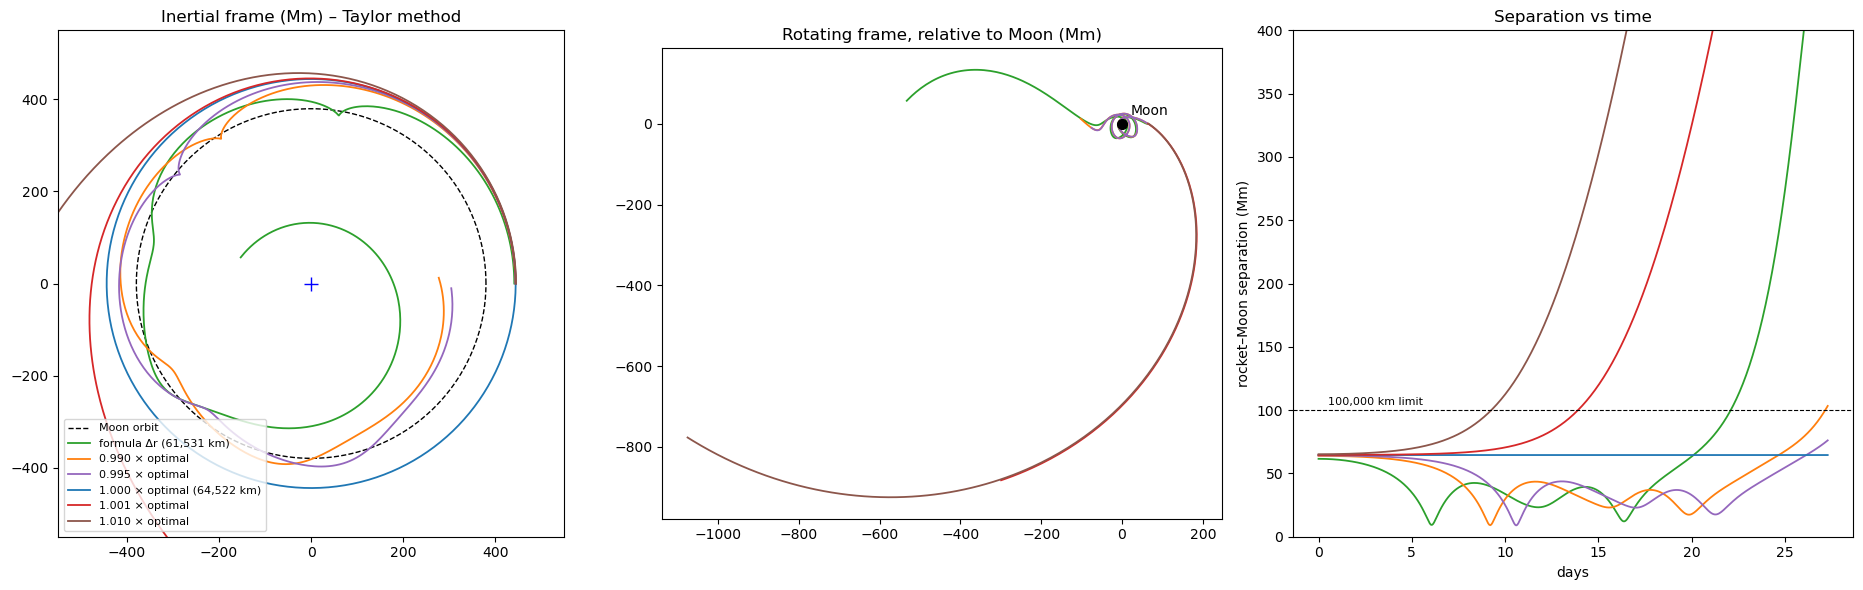

In [ ]:

# ---------------- constants ----------------
G  = 6.674e-11
mE, mM = 5.972e24, 7.348e22
R  = 3.844e8
w  = math.sqrt(G*(mE+mM)/R**3)          
T  = 2*math.pi/w                         
fE = mM/(mE+mM)*R                        
fM = mE/(mE+mM)*R                        
dr_approx = R*(mM/(3*mE))**(1/3)         

# exact L2 distance from the Moon (force balance for a co-rotating rocket)
def balance(dr):
    r = fM + dr
    return -G*mE/(r+fE)**2 - G*mM/dr**2 + w**2*r
dr_exact = brentq(balance, 3e7, 1e8, xtol=1e-3)

# ---------------- Earth & Moon positions / velocities ----------------
def bodies(t):
    c, s = math.cos(w*t), math.sin(w*t)
    return (-fE*c, -fE*s), (fM*c, fM*s)
def bodyvel(t):
    c, s = math.cos(w*t), math.sin(w*t)
    return (fE*w*s, -fE*w*c), (-fM*w*s, fM*w*c)

# ---------------- acceleration and jerk of the rocket ----------------
def acc_jerk(t, x, y, vx, vy):
    (xe, ye), (xm, ym)     = bodies(t)
    (uex, uey), (umx, umy) = bodyvel(t)
    ax = ay = jx = jy = 0.0
    for m, bx, by, bvx, bvy in ((mE, xe, ye, uex, uey), (mM, xm, ym, umx, umy)):
        dx, dy = x-bx, y-by
        d2 = dx*dx + dy*dy; d = math.sqrt(d2); d3 = d2*d; d5 = d3*d2
        wx, wy = vx-bvx, vy-bvy                 # velocity relative to the body
        dot = dx*wx + dy*wy
        ax += -G*m*dx/d3;  ay += -G*m*dy/d3
        jx += -G*m*(wx/d3 - 3*dot*dx/d5)
        jy += -G*m*(wy/d3 - 3*dot*dy/d5)
    return ax, ay, jx, jy

# ---------------- Taylor-expansion integrator ----------------
def taylor_orbit(dr, h=10.0, store_every=500):
    r = fM + dr
    x, y, vx, vy = r, 0.0, 0.0, w*r              # start at L2, co-rotating speed
    N = int(round(T/h)); h = T/N
    out = []; t = 0.0
    for k in range(N+1):
        if k % store_every == 0 or k == N:
            out.append((t, x, y, vx, vy))
        ax, ay, jx, jy = acc_jerk(t, x, y, vx, vy)
        x_new  = x  + vx*h + ax*h*h/2 + jx*h**3/6
        y_new  = y  + vy*h + ay*h*h/2 + jy*h**3/6
        vx_new = vx + ax*h + jx*h*h/2
        vy_new = vy + ay*h + jy*h*h/2
        x, y, vx, vy = x_new, y_new, vx_new, vy_new
        t += h
    return np.array(out).T                        # rows: t, x, y, vx, vy

# ---------------- scenarios ----------------
scen = [("formula Δr (61,531 km)",        dr_approx,       "tab:green"),
        ("0.990 × optimal",              0.990*dr_exact,  "tab:orange"),
        ("0.995 × optimal",              0.995*dr_exact,  "tab:purple"),
        ("1.000 × optimal (64,522 km)",  dr_exact,        "tab:blue"),
        ("1.001 × optimal",              1.001*dr_exact,  "tab:red"),
        ("1.010 × optimal",              1.010*dr_exact,  "tab:brown")]

th = np.linspace(0, 2*np.pi, 500)
fig, ax = plt.subplots(1, 3, figsize=(19, 6))
ax[0].plot(fM*np.cos(th)/1e6, fM*np.sin(th)/1e6, "k--", lw=1, label="Moon orbit")
ax[0].plot(0, 0, "b+", ms=10)

for name, dr, c in scen:
    t, x, y, vx, vy = taylor_orbit(dr)
    sep = np.hypot(x - fM*np.cos(w*t), y - fM*np.sin(w*t))
    xr =  x*np.cos(w*t) + y*np.sin(w*t) - fM          # rotating frame, relative to Moon
    yr = -x*np.sin(w*t) + y*np.cos(w*t)
    ax[0].plot(x/1e6, y/1e6, c=c, lw=1.3, label=name)
    ax[1].plot(xr/1e6, yr/1e6, c=c, lw=1.3)
    ax[2].plot(t/86400, sep/1e6, c=c, lw=1.3)
    print("%-30s separation after 1 orbit = %9.0f km, max = %9.0f km" % (name, sep[-1]/1e3, sep.max()/1e3))

ax[0].set_title("Inertial frame (Mm) – Taylor method"); ax[0].set_aspect("equal"); ax[0].legend(fontsize=8, loc="lower left")
ax[0].set_xlim(-550, 550); ax[0].set_ylim(-550, 550)
ax[1].plot(0, 0, "ko", ms=7); ax[1].annotate("Moon", (0, 0), textcoords="offset points", xytext=(6, 6))
ax[1].set_title("Rotating frame, relative to Moon (Mm)"); ax[1].set_aspect("equal")
ax[2].axhline(100, c="k", ls="--", lw=.8); ax[2].text(0.5, 104, "100,000 km limit", fontsize=8)
ax[2].set_ylim(0, 400); ax[2].set_xlabel("days"); ax[2].set_ylabel("rocket–Moon separation (Mm)")
ax[2].set_title("Separation vs time")
plt.tight_layout()
plt.savefig("L2_scenarios_taylor.png", dpi=110)
plt.show()

In [ ]:
# stdev of scilation on farroight plot , within certain limits as long as the oscilaltion is within the limits of percenst sa
# anothe rmteric rocket start an end 
#
# constraint of code  ,  
#
# do both runga kutta and taylor, use runga kutta to higher order? 
# 
# how fast do errors grow
# 
#runag kutta is serial menaing bottleneck is how fast runha kutta works
#  
#what are we marked on fro the poster: 
#
#
#   

